# 直進に揃えた上限と、マイコンへ送った指令

`research/motor_adjust` で変換をオンにし、下限は固定したまま上限だけを動かして、各速度でまっすぐになる値を書いた。

下限は右前進 13、左前進 13、右後退 36、左後退 36。最初の図はその上限で、変換前の数である。次の図は、その速度と上限から `research/motor_adjust/python/curve.py` が作り、`setMotorSpeed` でマイコンへ渡した指令である。正が前進、負が後退。スケッチは `1500 + trunc(指令 / 255 × 500)` µs をサーボへ書く。

速度 100 と 255 の後退は、左右に揺れながらの妥協である。速度 150 の後退で右 255・左 90 は差が大きくカクカクがひどかったので、右 95・左 90 を採用した。

末尾は、変換を使わず指令を直接入れた前進と後退の最終データと、その折れ線である。


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import japanize_matplotlib

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "flycar" / "behavior.py").exists():
    ROOT = ROOT.parent
CURVE = ROOT / "research" / "motor_adjust" / "python"
if str(CURVE) not in sys.path:
    sys.path.insert(0, str(CURVE))

from curve import map_wheel

SPEED = [50, 100, 150, 200, 255]
FORWARD_RIGHT = [255, 255, 255, 255, 255]
FORWARD_LEFT = [240, 245, 245, 200, 90]
REVERSE_RIGHT = [255, 175, 95, 100, 175]
REVERSE_LEFT = [230, 140, 90, 90, 80]
REVERSE_COMPROMISE = {100, 255}
FORWARD_LOW = 13
REVERSE_LOW = 36

RIGHT_COLOR = "#7eb6ff"
LEFT_COLOR = "#e2a100"


def forward_sent(speed, high):
    return map_wheel(speed, (FORWARD_LOW, high), (REVERSE_LOW, 255), True)


def reverse_sent(speed, high):
    return map_wheel(-speed, (FORWARD_LOW, 255), (REVERSE_LOW, high), True)


FORWARD_RIGHT_SENT = [forward_sent(s, h) for s, h in zip(SPEED, FORWARD_RIGHT)]
FORWARD_LEFT_SENT = [forward_sent(s, h) for s, h in zip(SPEED, FORWARD_LEFT)]
REVERSE_RIGHT_SENT = [reverse_sent(s, h) for s, h in zip(SPEED, REVERSE_RIGHT)]
REVERSE_LEFT_SENT = [reverse_sent(s, h) for s, h in zip(SPEED, REVERSE_LEFT)]


In [2]:
print("上限")
print(f"{'速度':>4}  {'前右':>4} {'前左':>4}  {'後右':>4} {'後左':>4}")
for row in zip(SPEED, FORWARD_RIGHT, FORWARD_LEFT, REVERSE_RIGHT, REVERSE_LEFT):
    print(f"{row[0]:4}  {row[1]:4} {row[2]:4}  {row[3]:4} {row[4]:4}")
print()
print("マイコンへの指令")
print(f"{'速度':>4}  {'前右':>5} {'前左':>5}  {'後右':>5} {'後左':>5}")
for row in zip(
    SPEED,
    FORWARD_RIGHT_SENT,
    FORWARD_LEFT_SENT,
    REVERSE_RIGHT_SENT,
    REVERSE_LEFT_SENT,
):
    print(f"{row[0]:4}  {row[1]:5} {row[2]:5}  {row[3]:5} {row[4]:5}")


上限
  速度    前右   前左    後右   後左
  50   255  240   255  230
 100   255  245   175  140
 150   255  245    95   90
 200   255  200   100   90
 255   255   90   175   80

マイコンへの指令
  速度     前右    前左     後右    後左
  50     60    58    -79   -74
 100    108   104    -91   -77
 150    155   149    -71   -68
 200    203   160    -86   -78
 255    255    90   -175   -80


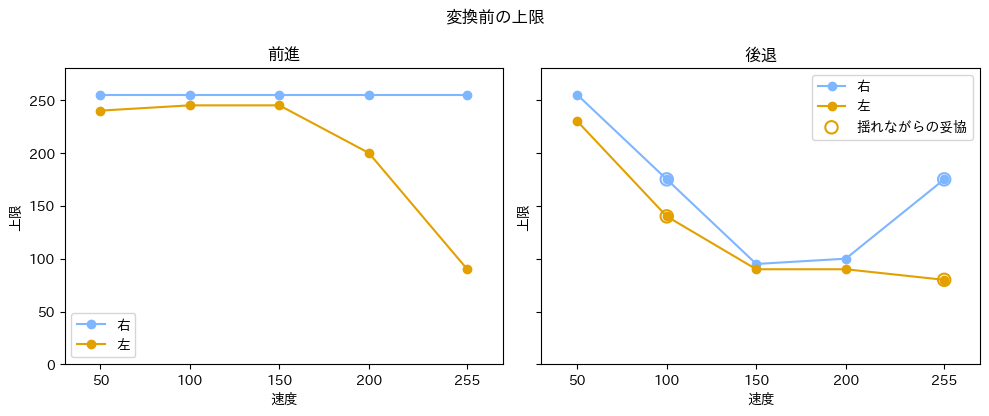

In [3]:
def draw(ax, right, left, title, ylabel, ylim):
    ax.plot(SPEED, right, color=RIGHT_COLOR, marker="o", label="右")
    ax.plot(SPEED, left, color=LEFT_COLOR, marker="o", label="左")
    if title == "後退":
        xs = [s for s in SPEED if s in REVERSE_COMPROMISE]
        ax.scatter(
            xs,
            [right[SPEED.index(s)] for s in xs],
            s=80,
            facecolors="none",
            edgecolors=RIGHT_COLOR,
            linewidths=1.5,
            zorder=3,
        )
        ax.scatter(
            xs,
            [left[SPEED.index(s)] for s in xs],
            s=80,
            facecolors="none",
            edgecolors=LEFT_COLOR,
            linewidths=1.5,
            zorder=3,
            label="揺れながらの妥協",
        )
    ax.set_title(title)
    ax.set_xlabel("速度")
    ax.set_ylabel(ylabel)
    ax.set_xticks(SPEED)
    ax.set_ylim(*ylim)
    ax.set_xlim(30, 275)
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
draw(axes[0], FORWARD_RIGHT, FORWARD_LEFT, "前進", "上限", (0, 280))
draw(axes[1], REVERSE_RIGHT, REVERSE_LEFT, "後退", "上限", (0, 280))
fig.suptitle("変換前の上限")
fig.tight_layout()


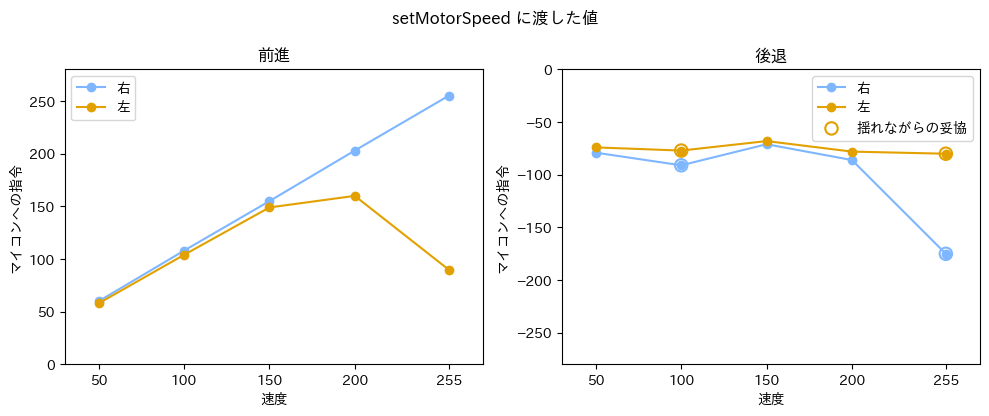

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
draw(
    axes[0],
    FORWARD_RIGHT_SENT,
    FORWARD_LEFT_SENT,
    "前進",
    "マイコンへの指令",
    (0, 280),
)
draw(
    axes[1],
    REVERSE_RIGHT_SENT,
    REVERSE_LEFT_SENT,
    "後退",
    "マイコンへの指令",
    (-280, 0),
)
fig.suptitle("setMotorSpeed に渡した値")
fig.tight_layout()


## 前進の生値

変換は使わず、右と左の指令を `setMotorSpeed` に直接入れた。前進でまっすぐになった組である。右 108 は、左 85 と左 104 の 2 回を残してある。


In [5]:
RAW_RIGHT = [
    21, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75,
    80, 85, 90, 95, 100, 108, 108, 110, 115, 120, 125,
]
RAW_LEFT = [
    16, 22, 26, 28, 33, 40, 44, 50, 58, 55, 58, 70,
    73, 79, 80, 83, 86, 85, 104, 87, 88, 91, 91,
]


def pulse_us(command):
    return 1500 + int(command / 255 * 500)


print(f"{'右':>4} {'左':>4} {'差':>4}  {'右µs':>6} {'左µs':>6}")
for right, left in zip(RAW_RIGHT, RAW_LEFT):
    print(f"{right:4} {left:4} {right - left:4}  {pulse_us(right):6} {pulse_us(left):6}")


   右    左    差     右µs    左µs
  21   16    5    1541   1531
  25   22    3    1549   1543
  30   26    4    1558   1550
  35   28    7    1568   1554
  40   33    7    1578   1564
  45   40    5    1588   1578
  50   44    6    1598   1586
  55   50    5    1607   1598
  60   58    2    1617   1613
  65   55   10    1627   1607
  70   58   12    1637   1613
  75   70    5    1647   1637
  80   73    7    1656   1643
  85   79    6    1666   1654
  90   80   10    1676   1656
  95   83   12    1686   1662
 100   86   14    1696   1668
 108   85   23    1711   1666
 108  104    4    1711   1703
 110   87   23    1715   1670
 115   88   27    1725   1672
 120   91   29    1735   1678
 125   91   34    1745   1678


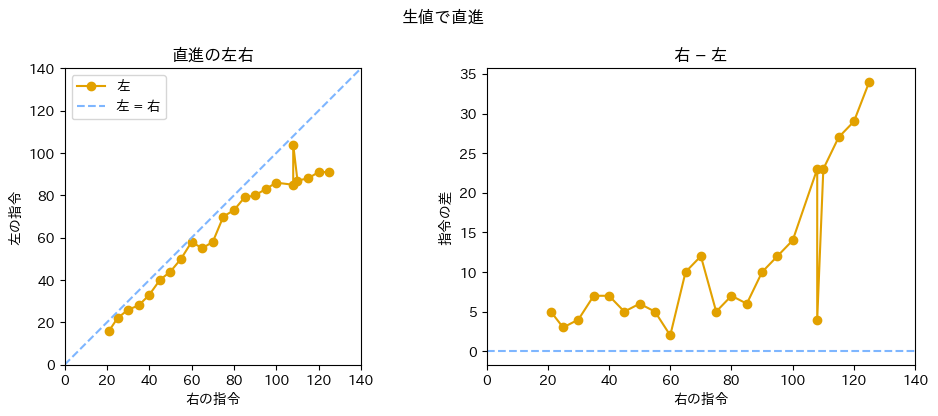

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

axes[0].plot(RAW_RIGHT, RAW_LEFT, color=LEFT_COLOR, marker="o", label="左")
axes[0].plot([0, 140], [0, 140], color=RIGHT_COLOR, linestyle="--", label="左 = 右")
axes[0].set_title("直進の左右")
axes[0].set_xlabel("右の指令")
axes[0].set_ylabel("左の指令")
axes[0].set_xlim(0, 140)
axes[0].set_ylim(0, 140)
axes[0].set_aspect("equal", adjustable="box")
axes[0].legend()

gap = [right - left for right, left in zip(RAW_RIGHT, RAW_LEFT)]
axes[1].plot(RAW_RIGHT, gap, color=LEFT_COLOR, marker="o")
axes[1].axhline(0, color=RIGHT_COLOR, linestyle="--")
axes[1].set_title("右 − 左")
axes[1].set_xlabel("右の指令")
axes[1].set_ylabel("指令の差")
axes[1].set_xlim(0, 140)

fig.suptitle("生値で直進")
fig.tight_layout()


## 後退の生値

変換は使わず、後退の右と左を直接入れた。まっすぐになった組である。表の数はページに入れた大きさで、マイコンへは負になって渡る。µs は 1500 より短い。


In [7]:
BACK_RIGHT = [36, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]
BACK_LEFT = [36, 47, 45, 54, 58, 63, 68, 73, 80, 82, 82, 84, 89, 94]


def reverse_us(magnitude):
    return 1500 - int(magnitude / 255 * 500)


print(f"{'右':>4} {'左':>4} {'差':>4}  {'右µs':>6} {'左µs':>6}")
for right, left in zip(BACK_RIGHT, BACK_LEFT):
    print(f"{right:4} {left:4} {right - left:4}  {reverse_us(right):6} {reverse_us(left):6}")


   右    左    差     右µs    左µs
  36   36    0    1430   1430
  40   47   -7    1422   1408
  45   45    0    1412   1412
  50   54   -4    1402   1395
  55   58   -3    1393   1387
  60   63   -3    1383   1377
  65   68   -3    1373   1367
  70   73   -3    1363   1357
  75   80   -5    1353   1344
  80   82   -2    1344   1340
  85   82    3    1334   1340
  90   84    6    1324   1336
  95   89    6    1314   1326
 100   94    6    1304   1316


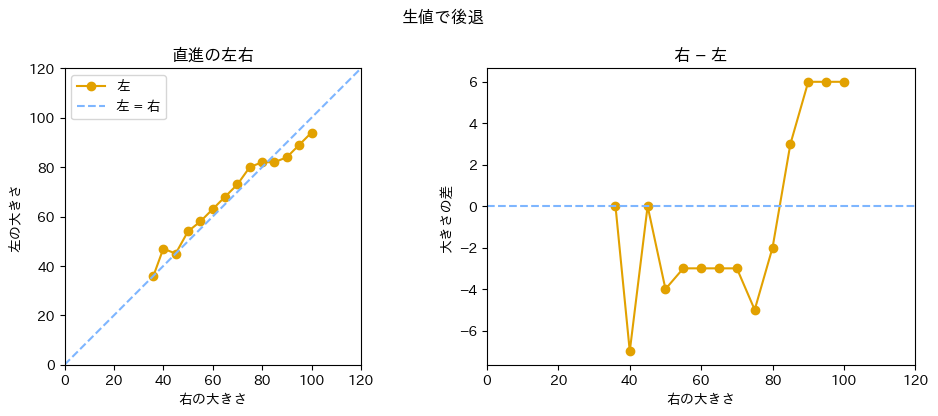

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

axes[0].plot(BACK_RIGHT, BACK_LEFT, color=LEFT_COLOR, marker="o", label="左")
axes[0].plot([0, 120], [0, 120], color=RIGHT_COLOR, linestyle="--", label="左 = 右")
axes[0].set_title("直進の左右")
axes[0].set_xlabel("右の大きさ")
axes[0].set_ylabel("左の大きさ")
axes[0].set_xlim(0, 120)
axes[0].set_ylim(0, 120)
axes[0].set_aspect("equal", adjustable="box")
axes[0].legend()

gap = [right - left for right, left in zip(BACK_RIGHT, BACK_LEFT)]
axes[1].plot(BACK_RIGHT, gap, color=LEFT_COLOR, marker="o")
axes[1].axhline(0, color=RIGHT_COLOR, linestyle="--")
axes[1].set_title("右 − 左")
axes[1].set_xlabel("右の大きさ")
axes[1].set_ylabel("大きさの差")
axes[1].set_xlim(0, 120)

fig.suptitle("生値で後退")
fig.tight_layout()


## 折れ線

まっすぐになる左右は、一本の比例には乗らない。右がある値を超えると、左の増え方が落ちる。折れ目は残差が最小になる位置を選ぶ。

右 108 の左 104 は、同じ右の左 85 と並んで残っている。フィットには左 85 の方だけを使う。


前進  折れ目 90  傾き 0.943 → 0.269  二乗平均 1.98  最大 4.9
  左 = -3.10 + 0.943×右
  右が 90 を超えると -0.673×(右−90) を足す

後退  折れ目 75  傾き 1.023 → 0.537  二乗平均 1.92  最大 4.4
  左 = 1.66 + 1.023×右
  右が 75 を超えると -0.487×(右−75) を足す


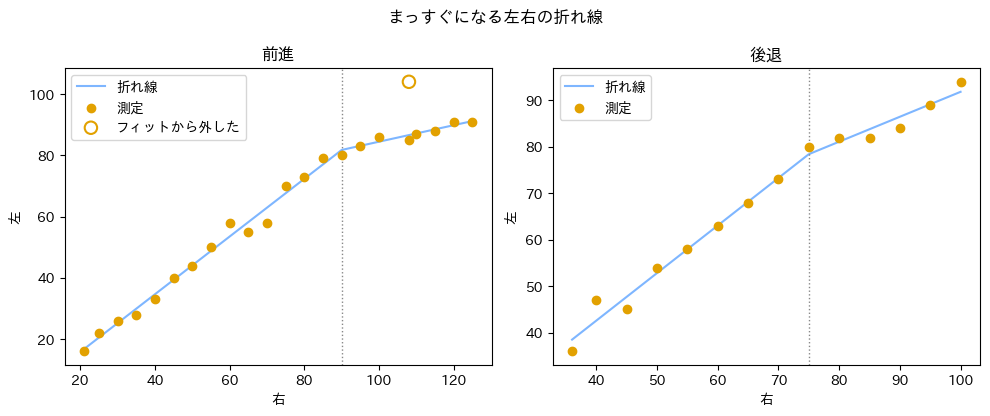

In [9]:
import numpy as np


def fit_hinge(x, y):
    """左 = a + b×右 + c×max(0, 右−折れ目)。折れ目は残差が最小の点。"""
    best = None
    for knot in np.unique(x)[2:-2]:
        hinge = np.maximum(0.0, x - knot)
        design = np.column_stack([np.ones_like(x), x, hinge])
        coef, *_ = np.linalg.lstsq(design, y, rcond=None)
        pred = design @ coef
        error = y - pred
        score = float(np.sqrt(np.mean(error**2)))
        if best is None or score < best[0]:
            best = (score, float(knot), coef, pred, error)
    return best


def hinge_at(coef, knot, x):
    x = np.asarray(x, float)
    offset, slope, bend = coef
    return offset + slope * x + bend * np.maximum(0.0, x - knot)


def report(title, knot, coef, error):
    offset, slope, bend = coef
    print(
        f"{title}  折れ目 {knot:.0f}  "
        f"傾き {slope:.3f} → {slope + bend:.3f}  "
        f"二乗平均 {np.sqrt(np.mean(error**2)):.2f}  "
        f"最大 {np.max(np.abs(error)):.1f}"
    )
    print(f"  左 = {offset:.2f} + {slope:.3f}×右")
    print(f"  右が {knot:.0f} を超えると {bend:.3f}×(右−{knot:.0f}) を足す")


forward_x = np.asarray(RAW_RIGHT, float)
forward_y = np.asarray(RAW_LEFT, float)
forward_use = ~((forward_x == 108) & (forward_y == 104))
forward = fit_hinge(forward_x[forward_use], forward_y[forward_use])
report("前進", forward[1], forward[2], forward[4])
print()

back_x = np.asarray(BACK_RIGHT, float)
back_y = np.asarray(BACK_LEFT, float)
back = fit_hinge(back_x, back_y)
report("後退", back[1], back[2], back[4])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
panels = (
    (axes[0], "前進", forward_x, forward_y, forward_use, forward),
    (axes[1], "後退", back_x, back_y, np.ones_like(back_x, dtype=bool), back),
)
for ax, title, x, y, use, fitted in panels:
    knot = fitted[1]
    grid = np.linspace(x.min(), x.max(), 200)
    ax.plot(grid, hinge_at(fitted[2], knot, grid), color=RIGHT_COLOR, label="折れ線")
    ax.scatter(x[use], y[use], color=LEFT_COLOR, zorder=3, label="測定")
    if not np.all(use):
        ax.scatter(
            x[~use],
            y[~use],
            s=80,
            facecolors="none",
            edgecolors=LEFT_COLOR,
            linewidths=1.5,
            zorder=4,
            label="フィットから外した",
        )
    ax.axvline(knot, color="#888888", linestyle=":", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("右")
    ax.set_ylabel("左")
    ax.legend()
fig.suptitle("まっすぐになる左右の折れ線")
fig.tight_layout()
